In [2]:
# importing libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Load cleaned dataset from Notebook 01
df = pd.read_csv("D:\Project\Customer-segmentation\data\cleaned_OR2_data.csv")
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])



print(f"Transactions Loaded: {len(df):,}")
print(f"Unique Customers  : {df['Customer ID'].nunique():,}")
df.head()

<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33712\3521566178.py:2: SyntaxWarning: invalid escape sequence '\P'
  df = pd.read_csv("D:\Project\Customer-segmentation\data\cleaned_OR2_data.csv")


Transactions Loaded: 396,470
Unique Customers  : 4,334


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSum
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Cell 3: Construct Customer-Level RFM + Extended Behavioral Features

In [4]:
# Reference date for Recency calculation (1 day after the latest transaction)
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Group by Customer ID to calculate base RFM and extended behavioral features
customer_df = df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),                       # Count of unique orders
    Monetary=('TotalSum', 'sum'),                           # Total spend across all purchases
    TotalQuantity=('Quantity', 'sum'),                      # Total items purchased
    TotalItems=('StockCode', 'nunique'),                    # Diversity of products bought
    AvgOrderValue=('TotalSum', lambda x: x.sum() / x.nunique() if x.nunique() > 0 else x.sum()) # Average Spend per Transaction
).reset_index()

# Calculate Interpurchase Interval / Average Days Between Purchases
def avg_days_between_orders(dates):
    unique_dates = pd.Series(dates.dt.date.unique()).sort_values()
    if len(unique_dates) <= 1:
        return 0.0
    return (unique_dates.diff().dt.days.dropna()).mean()

interpurchase = df.groupby('Customer ID')['InvoiceDate'].apply(avg_days_between_orders).reset_index()
interpurchase.columns = ['Customer ID', 'AvgInterpurchaseDays']

# Merge extended behavioral metrics
customer_features = pd.merge(customer_df, interpurchase, on='Customer ID')

print(f"Customer Feature Matrix Constructed: {customer_features.shape[0]:,} Unique Customers")
customer_features.head()

Customer Feature Matrix Constructed: 4,334 Unique Customers


,Customer ID,Recency,Frequency,Monetary,TotalQuantity,TotalItems,AvgOrderValue,AvgInterpurchaseDays
0,12346,326,1,77183.60,74215,1,77183.600000,0.000000
1,12347,2,7,4310.00,2458,103,78.363636,60.833333
2,12348,75,4,1437.24,2332,21,102.660000,94.333333
3,12349,19,1,1457.55,630,72,36.438750,0.000000
4,12350,310,1,294.40,196,16,36.800000,0.000000


Cell 4: Analyze Skewness Before Transformation

--- Skewness Values Before Log Transformation ---
Recency                  1.24
Frequency               11.98
Monetary                19.54
TotalQuantity           20.39
TotalItems               6.92
AvgOrderValue           46.23
AvgInterpurchaseDays     1.99
dtype: float64


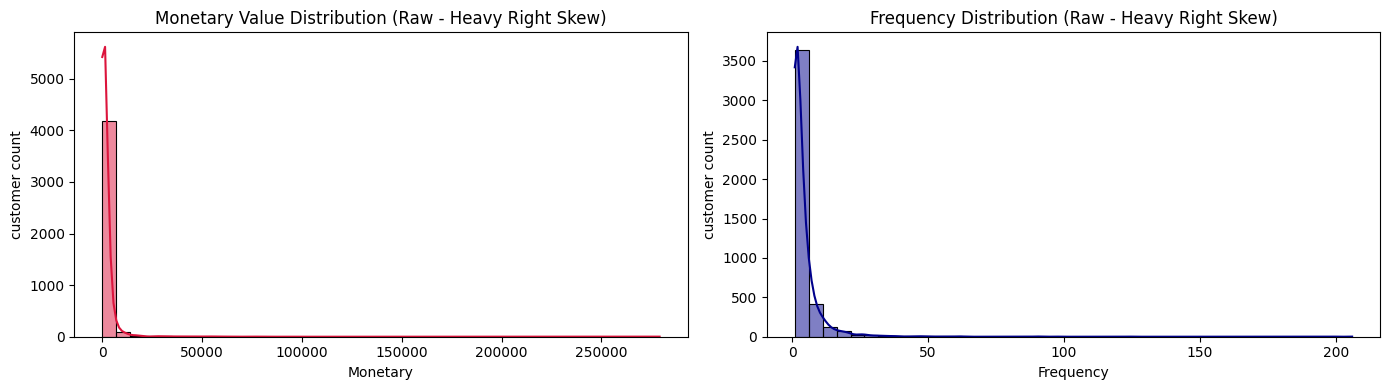

In [5]:
# Check raw skewness of continuous features
numerical_cols = ['Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'TotalItems', 'AvgOrderValue', 'AvgInterpurchaseDays']

print("--- Skewness Values Before Log Transformation ---")
print(customer_features[numerical_cols].skew().round(2))

# Visualize raw vs right-skewed features (Monetary & Frequency)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(customer_features['Monetary'], bins=40, kde=True, ax=axes[0], color='crimson')
axes[0].set_title("Monetary Value Distribution (Raw - Heavy Right Skew)")
axes[0].set_ylabel("customer count")

sns.histplot(customer_features['Frequency'], bins=40, kde=True, ax=axes[1], color='darkblue')
axes[1].set_title("Frequency Distribution (Raw - Heavy Right Skew)")
axes[1].set_ylabel("customer count")
plt.tight_layout()
plt.show()

Cell 5: Apply Log Transformation ($\log(x + 1)$)

In [6]:
# Create a copy for transformed features
log_features = customer_features.copy()

# Apply log1p transformation to handle zeros safely: log(x + 1)
for col in numerical_cols:
    log_features[f'{col}_log'] = np.log1p(log_features[col])

print("--- Skewness Values After Log Transformation ---")
log_cols = [f'{col}_log' for col in numerical_cols]
print(log_features[log_cols].skew().round(2))

--- Skewness Values After Log Transformation ---
Recency_log                -0.38
Frequency_log               1.21
Monetary_log                0.40
TotalQuantity_log           0.08
TotalItems_log             -0.24
AvgOrderValue_log           1.20
AvgInterpurchaseDays_log   -0.29
dtype: float64


Cell 6: Identify & Remove Extreme Log Outliers (IQR on Log Scale)

In [7]:
# Compute IQR bounds on the log-transformed Monetary and Frequency features
Q1 = log_features['Monetary_log'].quantile(0.25)
Q3 = log_features['Monetary_log'].quantile(0.75)
IQR = Q3 - Q1

# Define threshold bounds (using 3 * IQR on log scale to only remove extreme anomalies)
lower_bound = Q1 - (3 * IQR)
upper_bound = Q3 + (3 * IQR)

# Filter genuine extreme anomalies
clean_customer_features = log_features[
    (log_features['Monetary_log'] >= lower_bound) & 
    (log_features['Monetary_log'] <= upper_bound)
]

removed_count = len(log_features) - len(clean_customer_features)
print(f"Original Customers: {len(log_features):,}")
print(f"Extreme Outliers Removed (Log-scale IQR): {removed_count}")
print(f"Final Customer Profiles Remaining: {len(clean_customer_features):,}")

Original Customers: 4,334
Extreme Outliers Removed (Log-scale IQR): 2
Final Customer Profiles Remaining: 4,332


Cell 7: Plot Log-Transformed Features

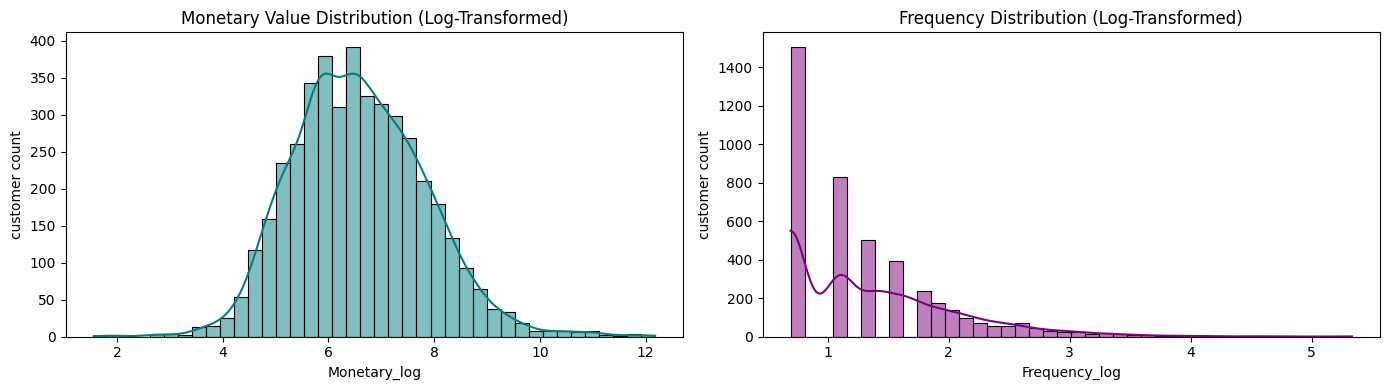

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(clean_customer_features['Monetary_log'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].set_title("Monetary Value Distribution (Log-Transformed)")
axes[0].set_ylabel("customer count")
sns.histplot(clean_customer_features['Frequency_log'], bins=40, kde=True, ax=axes[1], color='purple')
axes[1].set_title("Frequency Distribution (Log-Transformed)")
axes[1].set_ylabel("customer count")
plt.tight_layout()
plt.show()

In [10]:
clean_customer_features.to_csv("D:\Project\Customer-segmentation\data\cleanCustomerFeature.csv", index=False)


<>:1: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_33712\1730363424.py:1: SyntaxWarning: invalid escape sequence '\P'
  clean_customer_features.to_csv("D:\Project\Customer-segmentation\data\cleanCustomerFeature.csv", index=False)
